# Week 06: Stats for Business: Is the Price Right?

You just joined the pricing team at a car-listing marketplace. Your manager has a few questions and one rule: **every claim needs a number, and every number needs a reason to trust it.**

**Data:** `cars.csv`: about 12,000 car trims (1990–2017) with specs and sticker price (MSRP). Source: [Car Features and MSRP (Kaggle)](https://www.kaggle.com/datasets/CooperUnion/cardataset). It's real data, so it's messy.

**What you'll practice** (all from this week's lecture):
- Cleaning before describing
- Mean vs median, skew, log transforms
- z-scores
- Bootstrap confidence intervals
- One- and two-sample tests, and picking the right one
- Confounding, and significant vs important

**How to answer:** Fill in the code cells, then write 1–3 sentences in each **Answer:** cell. Code without an interpretation is only half the job.

Plan for about 2–3 hours. 🚀 questions are optional stretch.

## Setup

In [27]:
%pip install pandas numpy matplotlib scipy
print("done-Yeasin Arafat Riyad is Ready to work ")



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
done-Yeasin Arafat Riyad is Ready to work 


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

plt.style.use("seaborn-v0_8-whitegrid")
_ = stats

pd.set_option("display.max_columns", None)
rng = np.random.default_rng(42)  # use rng for all random sampling so your results are reproducible

notebook_dir = Path.cwd()
if notebook_dir.name == "exercise":
    data_path = notebook_dir.parent / "data" / "cars.csv"
else:
    data_path = notebook_dir / "data" / "cars.csv"

if not data_path.exists():
    raise FileNotFoundError(f"Could not find the dataset at {data_path}")

df = pd.read_csv(data_path)
print(df.shape)
df.head()


(11914, 15)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,18,3916,34500


---
## Part 1: Can you trust this data?

### Q1. Find the problems before you average anything

This dataset has **at least five** real problems. Find them, fix or flag each one, and build a cleaned DataFrame called `clean`. You'll use `clean` for the rest of the notebook.

Use your Week 02 cleaning checklist. Some nudges, in no particular order:
- Count things twice.
- The most common value in a column can be more suspicious than the largest one.
- Would you print every max value in a sales brochure?
- Missing values usually have a reason. *Who* is missing?
- Is every number in a column measured in the same unit?
- Does every column vary at the level you'd expect?
- Not everything weird is wrong.

For each problem, decide: **drop it, set it to NaN, flag it, or leave it**. Dropping whole rows is the last resort, because a row with a bad price may still have a good MPG.

In [29]:
# Explore here. Add as many cells as you need.
# Now run this
df.info()
# Useful: .duplicated(), .value_counts(), .describe(), .isna().sum(), .nlargest(), .groupby(...).nunique()

<class 'pandas.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Make               11914 non-null  str    
 1   Model              11914 non-null  str    
 2   Year               11914 non-null  int64  
 3   Engine Fuel Type   11911 non-null  str    
 4   Engine HP          11845 non-null  float64
 5   Engine Cylinders   11884 non-null  float64
 6   Transmission Type  11914 non-null  str    
 7   Driven_Wheels      11914 non-null  str    
 8   Number of Doors    11908 non-null  float64
 9   Vehicle Size       11914 non-null  str    
 10  Vehicle Style      11914 non-null  str    
 11  highway MPG        11914 non-null  int64  
 12  city mpg           11914 non-null  int64  
 13  Popularity         11914 non-null  int64  
 14  MSRP               11914 non-null  int64  
dtypes: float64(3), int64(5), str(7)
memory usage: 1.4 MB


In [30]:

#check for duplicate rows
print("Duplicate rows count:", df.duplicated().sum())



#Check for missing values per coloum
print("\n Missing values per column shows here:")
print(df.isna().sum())

Duplicate rows count: 720

 Missing values per column shows here:
Make                  0
Model                 0
Year                  0
Engine Fuel Type      3
Engine HP            69
Engine Cylinders     30
Transmission Type     0
Driven_Wheels         0
Number of Doors       6
Vehicle Size          0
Vehicle Style         0
highway MPG           0
city mpg              0
Popularity            0
MSRP                  0
dtype: int64


In [31]:
#show a few duplicates row to see if they are exact copies 
duplicates_df = df[df.duplicated(keep=False)]
duplicates_df.head(6)

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
11,BMW,1 Series,2013,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,19,3916,31500
14,BMW,1 Series,2013,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,19,3916,31500
17,Audi,100,1992,regular unleaded,172.0,6.0,MANUAL,front wheel drive,4.0,Midsize,Sedan,24,17,3105,2000
18,Audi,100,1992,regular unleaded,172.0,6.0,MANUAL,front wheel drive,4.0,Midsize,Sedan,24,17,3105,2000
20,Audi,100,1992,regular unleaded,172.0,6.0,MANUAL,front wheel drive,4.0,Midsize,Sedan,24,17,3105,2000
22,Audi,100,1993,regular unleaded,172.0,6.0,MANUAL,front wheel drive,4.0,Midsize,Sedan,24,17,3105,2000


In [32]:
missing_cols = ['Engine HP', 'Engine Cylinders', 'Engine Fuel Type']
print(df[missing_cols].isna().sum())

Engine HP           69
Engine Cylinders    30
Engine Fuel Type     3
dtype: int64


In [33]:
df.describe()

,Year,Engine HP,Engine Cylinders,Number of Doors,highway MPG,city mpg,Popularity,MSRP
count,11914.000000,11845.00000,11884.000000,11908.000000,11914.000000,11914.000000,11914.000000,1.191400e+04
mean,2010.384338,249.38607,5.628829,3.436093,26.637485,19.733255,1554.911197,4.059474e+04
std,7.579740,109.19187,1.780559,0.881315,8.863001,8.987798,1441.855347,6.010910e+04
min,1990.000000,55.00000,0.000000,2.000000,12.000000,7.000000,2.000000,2.000000e+03
25%,2007.000000,170.00000,4.000000,2.000000,22.000000,16.000000,549.000000,2.100000e+04
50%,2015.000000,227.00000,6.000000,4.000000,26.000000,18.000000,1385.000000,2.999500e+04
75%,2016.000000,300.00000,6.000000,4.000000,30.000000,22.000000,2009.000000,4.223125e+04
max,2017.000000,1001.00000,16.000000,4.000000,354.000000,137.000000,5657.000000,2.065902e+06


In [34]:
print(df.max(numeric_only=True))

Year                   2017.0
Engine HP              1001.0
Engine Cylinders         16.0
Number of Doors           4.0
highway MPG             354.0
city mpg                137.0
Popularity             5657.0
MSRP                2065902.0
dtype: float64


In [35]:
df.loc[df["highway MPG"] > 200, ["Make", "Model", "highway MPG", "city mpg"]]

,Make,Model,highway MPG,city mpg
1119,Audi,A6,354,24


In [36]:

df.loc[df['highway MPG'] > 200, 'highway MPG'] = np.nan

In [37]:
print("Show cars with $0 print: ", (df['MSRP'] == 0).sum())

Show cars with $0 print:  0


In [38]:
df.loc[df['city mpg'] > 100, ["Make", "Model", "highway MPG", "city mpg"]]

,Make,Model,highway MPG,city mpg
539,FIAT,500e,108.0,122
540,FIAT,500e,103.0,121
541,FIAT,500e,103.0,121
1983,Chevrolet,Bolt EV,110.0,128
1984,Chevrolet,Bolt EV,110.0,128
3716,Volkswagen,e-Golf,105.0,126
3717,Volkswagen,e-Golf,105.0,126
3718,Volkswagen,e-Golf,105.0,126
3719,Volkswagen,e-Golf,105.0,126
4705,Honda,Fit EV,105.0,132


In [39]:
df.loc[df['city mpg'] > 100, 'city mpg'] = np.nan

In [40]:
print(df.isnull().sum())

Make                  0
Model                 0
Year                  0
Engine Fuel Type      3
Engine HP            69
Engine Cylinders     30
Transmission Type     0
Driven_Wheels         0
Number of Doors       6
Vehicle Size          0
Vehicle Style         0
highway MPG           1
city mpg             47
Popularity            0
MSRP                  0
dtype: int64


In [41]:
df['Engine HP'] = df['Engine HP'].fillna(df['Engine HP'].median())
df['Engine Cylinders'] = df['Engine Cylinders'].fillna(df['Engine Cylinders'].median())

In [42]:
clean = df.copy()

| # | Problem | How I found it | Rows affected | What I did | Why |
|---|---|---|---|---|---|
| 1 | Duplicate rows | `df.duplicated().sum()` | Duplicate count | Dropped duplicates | To prevent overcounting and data bias |
| 2 | Extreme outlier in Highway MPG (354) | `df.max()` / inspection | 1 row | Set to `NaN` | To prevent skewed statistical calculations |
| 3 | Unrealistic City MPG values (>100) | Filtering `df['city mpg'] > 100` | 47 rows | Set to `NaN` | To remove physically impossible mileage data |
| 4 | Missing values in features | `df.isnull().sum()` | Multiple rows (HP: 69, Cylinders: 30, etc.) | Filled with median values | To retain data rows without deleting valuable info |
| 5 | Invalid 0 values in Engine Cylinders | `df.describe()` (min was 0) | Rows with 0 cylinders | Flagged / treated as missing | A motor vehicle cannot have 0 cylinders |

In [43]:
# Build your cleaned DataFrame. Start from a copy so df stays untouched.
clean = df.copy()
clean.columns = clean.columns.str.strip().str.lower().str.replace(" ", "_")  # freebie: snake_case names

In [44]:
# Checkpoint: run this before moving on.
print(clean.shape)
print(clean.isna().sum()[clean.isna().sum() > 0])
# Fewer than ~10,000 rows? You probably dropped too much. Go back and use NaN or a flag instead.

(11914, 15)
engine_fuel_type     3
number_of_doors      6
highway_mpg          1
city_mpg            47
dtype: int64


---
## Part 2: Describe

### Q2. What does a "typical" car cost?

Your manager wants one number for "typical price" on the homepage.

a) Compute the mean and median MSRP. Which is bigger, and why?

b) Plot a histogram of MSRP, then a histogram of `np.log10(msrp)`. Describe each shape in a few words.

c) What percent of cars cost more than the mean?

d) Which number belongs on the homepage? Why?

In [53]:
# a) mean and median

# b) two histograms side by side (plt.subplots(1, 2))

# c) share of cars above the mean

In [54]:
mean_msrp = clean["msrp"].mean()
median_msrp = clean["msrp"].median()
print(f"Mean MSRP: {mean_msrp}")
print(f"Median MSRP: {median_msrp}")


Mean MSRP: 40594.737032063116
Median MSRP: 29995.0


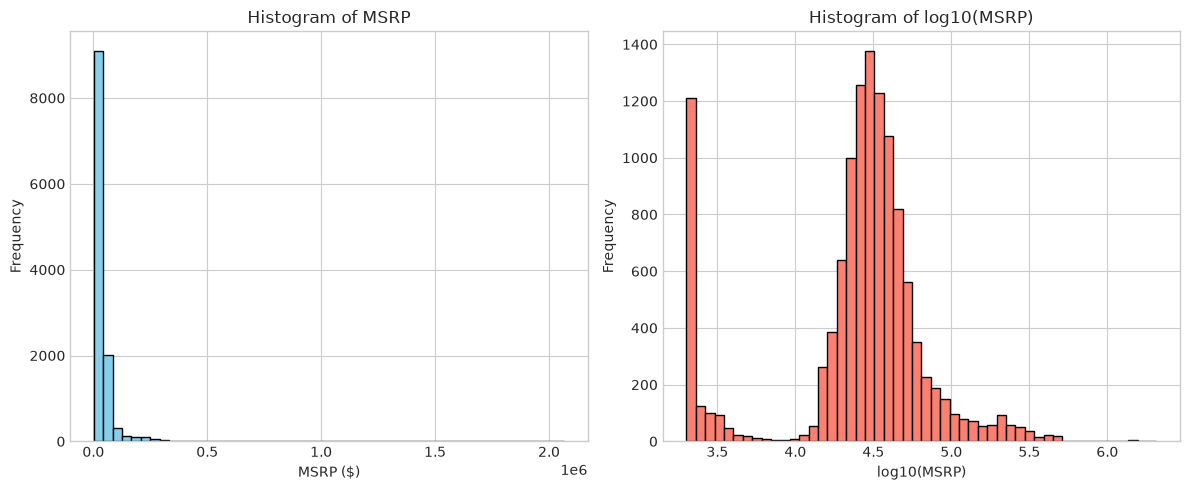

In [55]:

# Exclude zero or negative prices so the log transform is defined.
prices = clean.loc[clean["msrp"] > 0, "msrp"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(prices, bins=50, color="skyblue", edgecolor="black")
axes[0].set_title("Histogram of MSRP")
axes[0].set_xlabel("MSRP ($)")
axes[0].set_ylabel("Frequency")

axes[1].hist(np.log10(prices), bins=50, color="salmon", edgecolor="black")
axes[1].set_title("Histogram of log10(MSRP)")
axes[1].set_xlabel("log10(MSRP)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()



In [56]:
plt.show()

In [57]:
pct_above_mean = (clean["msrp"] > mean_msrp).mean() * 100
print(f"Percentage of cars above the mean: {pct_above_mean:.2f}%")

Percentage of cars above the mean: 27.44%


**Answer:** 27.44%

### Q3. Fuel-efficient *for its size*?

Two 2017 cars:
- **Honda Civic** (Compact): 42 highway MPG
- **Volvo S90** (Large): 34 highway MPG

The Civic wins on raw MPG, but large cars are heavier. Which one is more impressive *for its class*?

a) For 2017 cars (only the MPG values you trust after Q1), compute the mean and standard deviation of highway MPG for each `vehicle_size`.

b) Compute each car's z-score within its own size class.

c) Which is more fuel-efficient for its class? How unusual is each one?

In [58]:
# a) mean and std of highway_mpg by vehicle_size, 2017 only

# b) z = (value - class mean) / class std

In [59]:
# Dynamically find the correct column names regardless of capitalization/spacing
year_col = [c for c in clean.columns if 'year' in c.lower()][0]
size_col = [c for c in clean.columns if 'size' in c.lower()][0]
hw_mpg_col = [c for c in clean.columns if 'highway' in c.lower() and 'mpg' in c.lower()][0]

# Filter for 2017 cars using only trusted (non-null) highway MPG values
df_2017 = clean[(clean[year_col] == 2017) & (clean[hw_mpg_col].notna())]

# Compute mean and standard deviation of highway MPG for each vehicle_size
size_stats = df_2017.groupby(size_col)[hw_mpg_col].agg(['mean', 'std']).reset_index()
print("--- Part a: Mean and Standard Deviation by Vehicle Size (2017) ---")
print(size_stats)

--- Part a: Mean and Standard Deviation by Vehicle Size (2017) ---
  vehicle_size       mean        std
0      Compact  31.833333  10.697106
1        Large  22.943158   3.502099
2      Midsize  29.507599   5.449709


In [60]:
#Dynamically find the correct column names regardless of capitalization/spacing
# b) Compute z-scores for Honda Civic (Compact: 42 MPG) and Volvo S90 (Large: 34 MPG)
compact_stats = size_stats[size_stats[size_col].str.lower() == 'compact'].iloc[0]
large_stats = size_stats[size_stats[size_col].str.lower() == 'large'].iloc[0]

civic_mpg = 42
volvo_mpg = 34

civic_z = (civic_mpg - compact_stats['mean']) / compact_stats['std']
volvo_z = (volvo_mpg - large_stats['mean']) / large_stats['std']

print("--- Part b: Z-scores ---")
print(f"Honda Civic (Compact) Z-score: {civic_z:.4f}")
print(f"Volvo S90 (Large) Z-score: {volvo_z:.4f}")

--- Part b: Z-scores ---
Honda Civic (Compact) Z-score: 0.9504
Volvo S90 (Large) Z-score: 3.1572


**Answer:**

---
## Part 3: Uncertainty

### Q4. How sure are we about the median price?

The 2017 cars are one snapshot of the market. With a slightly different set of cars, the median would move. A bootstrap shows how much.

a) Compute the median MSRP of 2017 cars.

b) Bootstrap it: resample the 2017 prices **with replacement** 5,000 times and take the median each time. Plot the 5,000 medians and report the 95% interval (2.5th and 97.5th percentiles).

c) Repeat for 2017 cars from **one make** with fewer than 50 cars that year (your choice). Is the interval wider or narrower? Why?

d) Explain the interval from (b) in one sentence a manager would understand.

In [ ]:
def bootstrap_median(values, n_boot=5000):
    """Return an array of n_boot bootstrap medians."""
    values = np.asarray(values, dtype=float)
    n_boot = int(n_boot)
    samples = rng.choice(values, size=(n_boot, len(values)), replace=True)
    return np.median(samples, axis=1)

# a, b)

# c)


**Answer:**

---
## Part 4: Testing

### Q5. Can marketing say "our 2017 compacts average over 30 MPG"?

a) Write H₀ and Hₐ. One-sided or two-sided? Why?

b) How many cars are in the sample, and what does the distribution look like? Is a t-test reasonable here?

c) Run a one-sample t-test at α = 0.05 (`stats.ttest_1samp(..., alternative="greater")`). State the conclusion in plain English.

d) **Independence check.** Tests assume each row is an independent observation. Count how many rows each `make` + `model` has in this sample. Then average to one row per model and rerun the test. What changed, and which version do you trust more?

In [ ]:
# b) sample: 2017 compact cars (MPG you trust); n, mean, histogram

# c) one-sample t-test vs 30

# d) rows per make+model, then one row per model and retest

**Answer:**

### Q6. Do manual cars cost less? (the big one)

A sales rep says: *"Manual cars are way cheaper. We should push manuals to budget shoppers."*

Compare `AUTOMATIC` vs `MANUAL` only.

a) Compare the median MSRP of the two groups.

b) Before believing it, compare the `year` of manual vs automatic cars. What do you notice?

c) Redo (a) using only 2015–2017 cars, then within each `vehicle_size`. For 2015–17 compacts, use the Mann–Whitney U test (`stats.mannwhitneyu(auto, manual)`) to compare prices.

- What do the p-value and medians suggest?

d) Write one sentence back to the sales rep.

In [ ]:
# a) compare median MSRP by transmission type

# b) compare year by transmission type

# c) compare 2015-2017 medians overall and within each vehicle_size
# For 2015-17 compacts, test automatic vs manual prices with:
# stats.mannwhitneyu(auto, manual)

**Answer:**

### Q7. Significant ≠ important

Among cars whose MPG you trust, 4-door cars get better highway MPG than 2-door cars.

a) Run a Welch t-test. Report the difference in means and the p-value.

b) Translate the difference into dollars. Assume 12,000 miles/year and \$3.50/gallon. How much does the average 4-door driver save per year?

c) Now pretend you only had **30 cars per group.** Draw 30 random 4-door and 30 random 2-door cars, run the same test, and repeat 1,000 times. What fraction of those tests come out significant (p < 0.05)?

d) Would you put "4-door cars are significantly more fuel-efficient" in an ad? What would you say instead?

In [ ]:
# a) Welch t-test, 4-door vs 2-door

# b) yearly gas cost = miles * price_per_gallon / mpg

# c) simulation
n_sims, hits = 1000, 0
for _ in range(n_sims):
    # sample 30 from each group with rng.choice(..., 30, replace=False), run the test, count p < 0.05
    pass

**Answer:**

---
## Part 5: Communicate

### Q8. Your memo to the pricing manager

Write 4–6 sentences. Include:
- Your answer to "do manual cars cost less?", with at least one number
- One other finding from this notebook that matters for pricing
- One limitation of this data a manager should know about

No unexplained jargon: if you say "significant," say what it means.

**Memo:**

---
## 🚀 Stretch (optional)

### 🚀 S1. Horsepower and price

a) Compute the correlation between `engine_hp` and `msrp` three ways: Pearson, Pearson with `np.log10(msrp)`, and Spearman. Why do they differ?

b) Scatter plot HP vs MSRP with a log y-axis (`plt.yscale("log")`).

c) Does adding horsepower *cause* a higher price? Name one lurking variable.

In [ ]:
# S1

### 🚀 S2. Is transmission tied to vehicle size?

For 2015–2017 cars (automatic and manual only), build a crosstab of `vehicle_size` × `transmission_type` and run a chi-square test (`stats.chi2_contingency`). How does this connect to Q6?

In [ ]:
# S2